# From decision rules to a discrimination audit

**Part 1 — A worked lesson.** You will trace a screening decision, compare access, discover a denial pattern, distinguish unequal outcomes from unequal errors, and evaluate two changes to the rule.

**Setup:** Open this notebook with a Python 3 Jupyter kernel that has `pandas` and `matplotlib`. Run from top to bottom. The 16 records are built into the notebook; no download is needed. Predict each cell’s output before you run it. Saved outputs support classroom use if your kernel is unavailable.

## 1. Meet the applicants and the decision

The setting is familiar from the previous lesson: an employer invites people to an **online analyst assessment**. This is a **new, fictional 16-applicant example** designed to teach implementation. An invitation is access to the next stage. It is not a job offer. The assessment can take all 16 applicants if needed.

| Field | Meaning | Role |
|---|---|---|
| `applicant` | Fake record ID | Trace decisions |
| `group` | Women or Men in this small example | Audit only |
| `experience` | 0–2 or 3+ years | Subgroup analysis only |
| `skill` | Skill score from the initial application | Screening input |
| `has_car` | 1 if the applicant owns a car | Screening input in the original rule |
| `qualifies` | 1 if an independent review says the applicant should advance | Reference label **only** |

For teaching, assume a separate blinded review of a relevant work sample was done for **every** applicant, including those declined by the screening rule. Its result gives the reference label `qualifies`; it is not an input to the rule or the old decision. Real audits must validate the reference and ask whether rejected candidates were assessed at all. The two group labels and their distributions are illustrative; they are not claims about real applicants.

Read W01 and M01. Which entries match? Which entries differ? Keep these two records in mind when we open the scoring rule.

In [1]:
import io  # Read the small CSV directly from this notebook.
import pandas as pd  # Work with readable tables.

raw_csv = '''applicant,group,experience,skill,has_car,qualifies
W01,Women,0–2 years,68,0,1
W02,Women,0–2 years,66,0,1
W03,Women,0–2 years,65,0,0
W04,Women,0–2 years,74,1,1
W05,Women,3+ years,75,0,1
W06,Women,3+ years,78,1,1
W07,Women,3+ years,71,0,1
W08,Women,3+ years,58,0,0
M01,Men,0–2 years,68,1,1
M02,Men,0–2 years,66,1,1
M03,Men,0–2 years,55,0,0
M04,Men,0–2 years,74,1,1
M05,Men,3+ years,75,1,1
M06,Men,3+ years,78,0,1
M07,Men,3+ years,71,1,1
M08,Men,3+ years,58,0,0'''
applicants = pd.read_csv(io.StringIO(raw_csv))  # One row per applicant.
print(applicants.to_string(index=False))  # Keep identifiers and all inputs visible.

applicant group experience  skill  has_car  qualifies
      W01 Women  0–2 years     68        0          1
      W02 Women  0–2 years     66        0          1
      W03 Women  0–2 years     65        0          0
      W04 Women  0–2 years     74        1          1
      W05 Women   3+ years     75        0          1
      W06 Women   3+ years     78        1          1
      W07 Women   3+ years     71        0          1
      W08 Women   3+ years     58        0          0
      M01   Men  0–2 years     68        1          1
      M02   Men  0–2 years     66        1          1
      M03   Men  0–2 years     55        0          0
      M04   Men  0–2 years     74        1          1
      M05   Men   3+ years     75        1          1
      M06   Men   3+ years     78        0          1
      M07   Men   3+ years     71        1          1
      M08   Men   3+ years     58        0          0


## 2. Open the decision rule

The original rule adds **10 points** for car ownership and invites anyone with a score of **70 or more**. Both choices are invented for this example. No model needs to be trained yet: we already know the rule and can audit its decisions directly.

- W01: 68 + 10 × 0 = **68** → no invitation.
- M01: 68 + 10 × 1 = **78** → invited.

Both applicants have skill 68 and both qualify according to the independent review. The group label does not appear in the rule. The extra points for car ownership are enough to explain the difference between these records in this rule.

In [2]:
audit = applicants.copy()  # Keep the source records intact.
audit["screen_score"] = audit["skill"] + 10 * audit["has_car"]  # Add the original car bonus.
audit["invited"] = audit["screen_score"] >= 70  # True means an invitation.
audit["denied"] = ~audit["invited"]  # True means no invitation.
fields = ["applicant", "skill", "has_car", "screen_score", "invited"]  # Pick columns for the trace.
pair = audit["applicant"].isin(["W01", "M01"])  # Mark the two records.
print(audit.loc[pair, fields].to_string(index=False))  # Check the hand calculation.

applicant  skill  has_car  screen_score  invited
      W01     68        0            68    False
      M01     68        1            78     True


## 3. Measure who gets access

For each group, divide **invited by all applicants in the group**. Count invitations before calculating a gap. In this example, a signed gap is always **Women minus Men**; a negative invitation gap means lower invitation rates for women in the observed records.

On paper: what evidence would you ask for before concluding that the disparity is unjustified?

In [3]:
by_group = audit.groupby("group", sort=False)  # Keep one set of rows for each audit group.
invited_count = by_group["invited"].sum()  # True counts as 1; False counts as 0.
applicant_count = by_group.size()  # Count both invited and denied applicants.
invitation_rate = invited_count / applicant_count  # Use all applicants in each group.
access = pd.DataFrame()  # Build the result one visible column at a time.
access["invited"] = invited_count  # Numerator.
access["applicants"] = applicant_count  # Denominator.
access["invitation_rate"] = invitation_rate  # Result.
print(access.to_string())  # Compare counts and rates side by side.
access_gap = invitation_rate["Women"] - invitation_rate["Men"]  # Use a fixed subtraction order.
print(f"Invitation gap (Women − Men): {100 * access_gap:+.1f} pp")  # Express the difference in percentage points.

       invited  applicants  invitation_rate
group                                      
Women        4           8             0.50
Men          6           8             0.75
Invitation gap (Women − Men): -25.0 pp


**Check:** Women 4/8 = 50%; men 6/8 = 75%; gap = −25 percentage points. This measures **access**, regardless of who qualifies. The numbers alone do not tell you what produced the gap.

## 4. Discover where denials concentrate

Test this rule: **Women AND 0–2 years of experience → denied**. The arrow summarizes a pattern in the records. It does not mean that everyone matching the left side was denied, or that gender caused the denial. The group is the audit category; the experience band is the context.

| Quantity | Question | Hand calculation |
|---|---|---:|
| Support | Out of the whole file, how often do group, context and denial occur together? | 3/16 = 18.75% |
| Confidence | Out of women with 0–2 years of experience, how many are denied? | 3/4 = 75% |
| Context baseline | Out of **all** applicants with 0–2 years of experience, how many are denied? | 4/8 = 50% |
| Extended lift | How large is the group’s rate relative to the pooled context rate? | 0.75/0.50 = 1.50 |
| Within-context gap | How much higher is the denial rate for women than for men in that band? | 3/4 − 1/4 = +50 pp |

Here, **confidence** is a rule frequency. It is different from the confidence level of a Wilson interval. The pooled context baseline includes the women; it is not the men’s rate.

In [4]:
junior = audit["experience"] == "0–2 years"  # Mark the context.
women = audit["group"] == "Women"  # Mark the audit group.
rule_rows = audit[junior & women]  # Antecedent: both conditions must be true.
rule_denied = rule_rows["denied"].sum()  # Count denials inside that antecedent.
support = rule_denied / len(audit)  # Denominator: all 16 records.
confidence = rule_denied / len(rule_rows)  # Denominator: the 4 matching records.
context_rate = audit.loc[junior, "denied"].mean()  # Mean of True/False gives 4/8 here.
extended_lift = confidence / context_rate  # Compare the two rates; the context rate is nonzero.
print(f"Support: {support:.2%}; confidence: {confidence:.0%}; extended lift: {extended_lift:.2f}")  # Check the arithmetic.

Support: 18.75%; confidence: 75%; extended lift: 1.50


Now compare the two **predeclared experience bands**. Preview the table before running the code: do you expect the +50-point gap in both bands? Show all four cells, even where there is no gap. In a larger audit, declare which contexts and minimum counts to use before highlighting a pattern. Four people per cell here is for arithmetic practice, not a recommended evidence threshold.

In [5]:
for band in ["0–2 years", "3+ years"]:  # Look at two named contexts only.
    context = audit[audit["experience"] == band]  # Filter to the current context.
    counts = context.groupby("group", sort=False)["denied"].agg(["sum", "size"])  # Count denials and people.
    counts = counts.rename(columns={"sum": "denials", "size": "applicants"})  # Label both counts.
    counts["denial_rate"] = counts["denials"] / counts["applicants"]  # Divide by the matching group count.
    print(f"Experience: {band}")  # Tell readers which subset is shown.
    print(counts.to_string())  # Show both groups including the smaller or zero-denial cells.

Experience: 0–2 years
       denials  applicants  denial_rate
group                                  
Women        3           4         0.75
Men          1           4         0.25
Experience: 3+ years
       denials  applicants  denial_rate
group                                  
Women        1           4         0.25
Men          1           4         0.25


**Interpretation:** Denials are 3/4 vs 1/4 in the 0–2 year band, and 1/4 vs 1/4 in the 3+ year band. The gap is concentrated in the junior band in this toy file. A small subgroup flag is a lead for process review. There is no population inference from these constructed records.

## 5. Measure missed opportunities using independent reference labels

A false negative is **qualifies AND not invited**. The false negative rate uses just the qualified applicants as its denominator. This is a different audit question from “Who was invited?”

| Group | True positives | False negatives | False positives | True negatives | False negative rate |
|---|---:|---:|---:|---:|---:|
| Women | 4 | 2 | 0 | 2 | 2/(4+2) = 33.3% |
| Men | 6 | 0 | 0 | 2 | 0/(6+0) = 0% |

If the only label you have is the original invitation, you can measure access and denials. You cannot calculate this missed-opportunity rate without a defensible reference.

In [6]:
qualified = audit["qualifies"] == 1  # Select reference-positive applicants.
missed = audit["denied"] & qualified  # Both conditions are needed for a false negative.
audit["missed_qualified"] = missed  # Save the row-level error for inspection.
missed_counts = audit.groupby("group", sort=False)["missed_qualified"].sum()  # False negatives by group.
qualified_counts = audit.groupby("group", sort=False)["qualifies"].sum()  # Count reference positives.
fnr = missed_counts / qualified_counts  # Both groups have qualified records in this example.
errors = pd.DataFrame()  # Build an error table for the two groups.
errors["false_negatives"] = missed_counts  # Numerator.
errors["qualified"] = qualified_counts  # Denominator.
errors["fnr"] = fnr.round(3)  # Round only for display.
print(errors.to_string())  # Show counts and rates.
print("Missed qualified applicants:", audit.loc[missed, "applicant"].tolist())  # Trace the burden to people.

       false_negatives  qualified    fnr
group                                   
Women                2          6  0.333
Men                  0          6  0.000
Missed qualified applicants: ['W01', 'W02']


## 6. Inspect what the implementation uses

Test W01’s rule twice while holding the skill score at 68. Change **only** car ownership. This is a controlled check of the implemented rule. It does not show what would happen to a real person if they acquired a car. Changing only `group` has no effect on this formula because `group` is not an input.

Keep three questions separate:
- **Treatment / rule use:** what changes a decision when other inputs are fixed? Does the rule explicitly use group or use a proxy? The car bonus is an unjustified barrier in this fictional online assessment; the score does not explicitly read gender.
- **Impact / outcomes:** who actually gains access?
- **Mistreatment / errors:** who is incorrectly screened out under the stated independent reference?

These are technical audit lenses; a flagged gap by itself does not determine legal discrimination.

In [7]:
fixed_skill = 68  # Hold W01's skill constant.
for car in [0, 1]:  # Vary only ownership in the rule.
    score = fixed_skill + 10 * car  # Apply the exact original formula.
    invited = score >= 70  # Translate the score into a decision.
    print(f"has_car={car}: score={score}, invited={invited}")  # See what actually changes.

has_car=0: score=68, invited=False
has_car=1: score=78, invited=True


## 7. Test changes and count who gains or loses

We compare three fixed policies on the **same 16 people**. The original rule is the baseline. Removing the bonus addresses feature relevance, and changing the cutoff tests a separate policy decision. The cutoffs are illustrations; we are not tuning on a test set or recommending that any cutoff be deployed.

1. **Original:** skill + 10 × has_car; invite at 70.
2. **No bonus, 70:** use skill only; do not change the cutoff.
3. **No bonus, 65:** use skill only; lower the cutoff to 65.

Before running: Can equal invitation rates hide increased errors? Which applicants do you predict will gain or lose access?

In [8]:
audit["skill_at_70"] = audit["skill"] >= 70  # Change the feature, keep the threshold.
audit["skill_at_65"] = audit["skill"] >= 65  # Change the threshold on the skill-only score.
policies = ["invited", "skill_at_70", "skill_at_65"]  # Compare three explicit alternatives.
policy_names = ["Original: 70", "No bonus: 70", "No bonus: 65"]  # Names for the table and plot.
policy_rows = []  # Collect one row for each policy.

for name, policy in zip(policy_names, policies):  # Pair display names with columns.
    decision = audit[policy]  # True means invited under the current policy.
    corrected = decision == qualified  # Check agreement with the reference for each person.
    new_misses = (~decision) & qualified  # Qualified people still denied.
    extra_invites = decision & (~qualified)  # Invitations without a positive reference.
    women_invited = decision[women].sum()  # Invited women out of 8 in this cohort.
    men_invited = decision[~women].sum()  # Invited men out of 8 in this two-group cohort.
    policy_rows.append([name, women_invited, men_invited, corrected.sum(),  # Keep counts.
                        new_misses.sum(), extra_invites.sum()])  # Add both error types.
columns = ["Policy", "W invited / 8", "M invited / 8", "Correct / 16", "FN", "FP"]  # Label counts.
comparison = pd.DataFrame(policy_rows, columns=columns)  # Turn the rows into a table.
print(comparison.to_string(index=False))  # Compare all three policies.

      Policy  W invited / 8  M invited / 8  Correct / 16  FN  FP
Original: 70              4              6            14   2   0
No bonus: 70              4              4            12   4   0
No bonus: 65              7              6            15   0   1


In [9]:
for alternative in ["skill_at_70", "skill_at_65"]:  # Compare each change with the original rule.
    gained = audit[alternative] & (~audit["invited"])  # Now invited, previously denied.
    lost = (~audit[alternative]) & audit["invited"]  # Now denied, previously invited.
    print(f"{alternative} — gains:", audit.loc[gained, "applicant"].tolist())  # Show who gains access.
    print(f"{alternative} — losses:", audit.loc[lost, "applicant"].tolist())  # Show who loses access.

skill_at_70 — gains: []
skill_at_70 — losses: ['M01', 'M02']
skill_at_65 — gains: ['W01', 'W02', 'W03']
skill_at_65 — losses: []


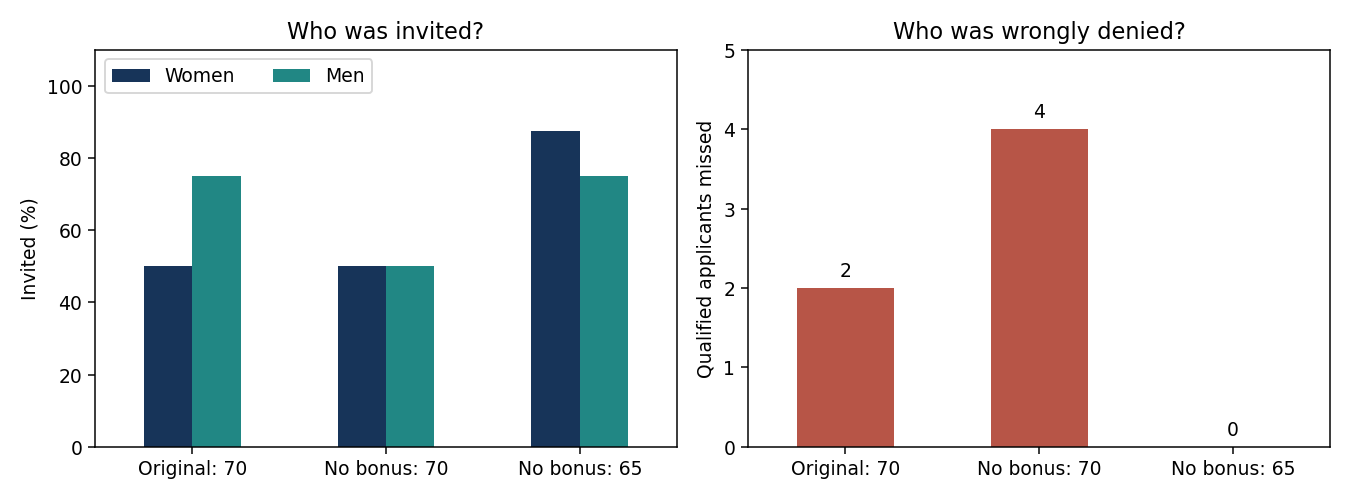

In [10]:
import matplotlib.pyplot as plt  # Make one comparison plot.

rates = audit.groupby("group", sort=False)[policies].mean().T * 100  # Convert rates to percent.
rates.index = policy_names  # Give the rows plain names.
misses = comparison.set_index("Policy")["FN"]  # Use the false negatives already counted.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))  # Put outcomes and errors side by side.
rates.plot.bar(ax=axes[0], color=["#173459", "#218784"], rot=0)  # Compare invitation rates.
axes[0].set(title="Who was invited?", ylabel="Invited (%)", ylim=(0, 110))  # Show the scale.
axes[0].legend(loc="upper left", ncols=2)  # Identify the groups.
misses.plot.bar(ax=axes[1], color="#B75547", rot=0)  # Plot the missed qualified applicants.
axes[1].bar_label(axes[1].containers[0], padding=4)  # Label all three counts, including zero.
axes[1].set(title="Who was wrongly denied?", ylabel="Qualified applicants missed",  # Name error.
            ylim=(0, 5), xlabel="", yticks=range(6))  # Count people on an integer scale.
fig.tight_layout()  # Leave room for text.
plt.show()  # Display the plot in class.

**Read the whole result.**

- Original: 4/8 women and 6/8 men invited; W01 and W02 are missed despite qualifying.
- No bonus at 70: both groups are at 4/8, but M01 and M02 now also miss out. Equalizing access rates by removing access for qualified people is not an improvement on the missed-opportunity objective.
- No bonus at 65: W01 and W02 gain access, and W03 is invited despite a negative reference. Both groups have zero false negatives **in this cohort**; women have 7/8 invited versus 6/8 men. Equal error rates for one kind of mistake do not imply equal invitation rates or equal rates of all errors.

Write three sentences: What would you change, who is affected by the change, and what would you need to check before using it on a new cohort? Consider the reference review’s quality, assessment capacity, the consequences of each type of error, and whether an appeal is available.

## Optional bridge to the original optimization

In this lab, students read a score, apply a decision boundary and compare policies. The original code goes further by changing how a model is **trained**: the loss measures prediction quality, the covariance condition constrains a proxy related to how decision scores vary with the audit attribute, and the optimizer searches for weights under that constraint. The resulting decisions still need a subgroup audit on separate data. A bound on score covariance is not the same quantity as a bound on the observed invitation gap.

Reading: Zafar et al., [Fairness Constraints: Mechanisms for Fair Classification](https://proceedings.mlr.press/v54/zafar17a.html), 2017. For error-rate constraints, see their separate [Fairness Beyond Disparate Treatment & Disparate Impact](https://doi.org/10.1145/3038912.3052660).

# Part 2 — Guided project work

Keep the original result as your baseline. Define the opportunity, cohort, error costs and improvement criterion before picking a winner.

### TODO A — Check a different cutoff
Pick a new skill-only cutoff before comparing results. Recompute invitation and false negative rates with numerators and denominators, and list changed IDs. What does your cutoff do to false positives? Try one threshold that is clearly too high or too low to show why one metric cannot choose a policy on its own.

### TODO B — Put the proposed policy under a capacity limit
Suppose there are 10 assessment places. Which policies in Part 1 still fit? Propose a transparent allocation rule for the remaining qualified candidates, including ties. Show who gains and who loses. State what happens to the remaining applicants and how you would handle accommodations or errors in the inputs.

### TODO C — Evaluate on a fresh cohort
Create or legitimately obtain a new cohort with independently defined reference labels. Set any tunable parameters using training/validation data only. Freeze the choice and report its outcomes on separate test data. Report who entered the dataset, who is missing and whether any group has too few cases. For a real population claim, justify sampling and uncertainty; for an exploration of many contexts, report the search rather than one selected finding.

### TODO D — Optional learned model
If you have enough suitable data, fit logistic regression using task-relevant inputs. Keep group fields for auditing. Evaluate qualified-applicant errors without training the model on its own screening decisions as though they were truth. Compare one model or feature change at a time on the same test records. The 16 demonstration rows are too few for a credible learned model.

**Submit:** a reproducible notebook, data origin and definitions, a table of counts and denominators, a before/after audit with who is affected, and a short decision memo that states limits.